# Evaluation results

Every number and figure here is read from committed measurement files; nothing is
typed in by hand. Run top to bottom from the repository root or `notebooks/`:

```
uv run --locked --group dev jupyter nbconvert --to notebook --execute --inplace notebooks/results.ipynb
```

| Evidence | Directory | Source |
|---|---|---|
| Policy-overhead benchmark (1,000 and 10,000 patients) | `results/raw/bench-20261030T174823Z/` | Actions run 41099548409, PR #55 |
| Access, bypass, audit-coverage and privacy summaries (1,009 patients) | `results/sanitized/ci-41205107037/` | see that directory's README |

Figures are written to `results/figures/` and are the ones used in the report and slides.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "results").exists() else Path.cwd().parent
BENCH = ROOT / "results/raw/bench-20261030T174823Z"
EVIDENCE = ROOT / "results/sanitized/ci-41205107037"
FIGURES = ROOT / "results/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
MIN_CELL = 11
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


def load_json(name):
    return json.loads((EVIDENCE / name).read_text())

## 1. Policy-overhead benchmark

Each role query ran as the real role user (enforced) and as `admin` with the same
`rules.json` filter and masks inlined (baseline): one cold run after a Trino restart,
then 10 warm runs. Overhead is `(enforced - baseline) / baseline` on the median.

In [2]:
summary = pd.concat(
    [pd.read_csv(BENCH / f"summary-{scale}.csv") for scale in (1000, 10000)], ignore_index=True
)
enforced = summary[summary.variant == "enforced"]
overhead = (
    enforced.groupby(["scale", "phase"])["overhead_pct_vs_baseline"]
    .agg(queries="count", median="median", min="min", max="max")
    .round(1)
)
overhead

queries  median   min   max
scale phase                             
1000  cold        12     9.4 -33.3  28.6
      warm        12    -2.0 -23.3  31.7
10000 cold        12    -4.4 -36.5  17.2
      warm        12     1.2 -11.1  10.1

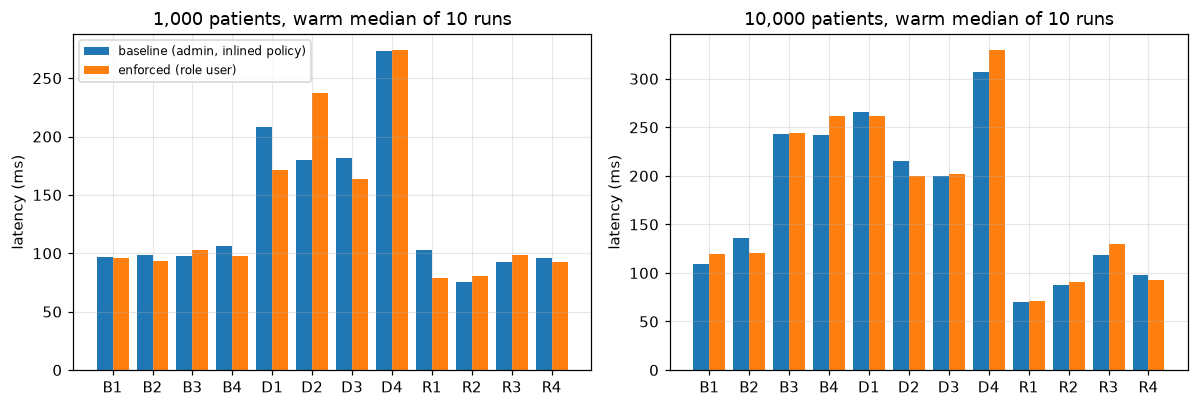

In [3]:
warm = summary[summary.phase == "warm"].pivot_table(
    index=["scale", "query_id"], columns="variant", values="median_ms"
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=False)
for ax, scale in zip(axes, (1000, 10000)):
    data = warm.loc[scale]
    x = range(len(data))
    ax.bar(
        [i - 0.2 for i in x], data["baseline"], width=0.4, label="baseline (admin, inlined policy)"
    )
    ax.bar([i + 0.2 for i in x], data["enforced"], width=0.4, label="enforced (role user)")
    ax.set_xticks(list(x), data.index)
    ax.set_title(f"{scale:,} patients, warm median of 10 runs")
    ax.set_ylabel("latency (ms)")
axes[0].legend(fontsize=8)
save(fig, "benchmark-latency")

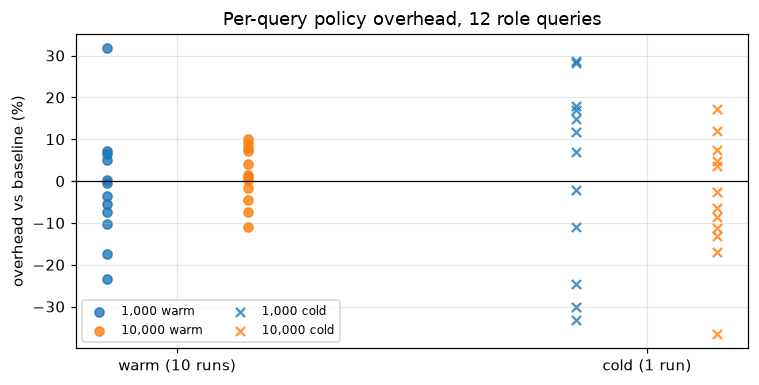

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for offset, (phase, marker) in enumerate((("warm", "o"), ("cold", "x"))):
    for scale, color in ((1000, "tab:blue"), (10000, "tab:orange")):
        values = enforced[(enforced.scale == scale) & (enforced.phase == phase)][
            "overhead_pct_vs_baseline"
        ]
        position = [offset * 2 + (0 if scale == 1000 else 0.6)] * len(values)
        label = f"{scale:,} {phase}"
        ax.scatter(position, values, marker=marker, color=color, label=label, alpha=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks([0.3, 2.3], ["warm (10 runs)", "cold (1 run)"])
ax.set_ylabel("overhead vs baseline (%)")
ax.set_title("Per-query policy overhead, 12 role queries")
ax.legend(fontsize=8, ncol=2)
save(fig, "benchmark-overhead")

In [5]:
verification = pd.concat(
    [pd.read_csv(BENCH / f"verification-{scale}.csv") for scale in (1000, 10000)],
    ignore_index=True,
)
storage = pd.concat(
    [pd.read_csv(BENCH / f"storage-{scale}.csv") for scale in (1000, 10000)], ignore_index=True
)
assert verification.fingerprints_match.all() and verification.unauthorized_rows.sum() == 0
display(
    verification.groupby("scale").agg(
        queries=("query_id", "count"),
        fingerprints_match=("fingerprints_match", "all"),
        unauthorized_rows=("unauthorized_rows", "sum"),
    )
)
storage.pivot_table(index="table", columns="scale", values=["table_rows", "stored_bytes"])

,queries,fingerprints_match,unauthorized_rows
scale,,,
1000,12,True,0.0
##[group]Run actions/upload-artifact@v4,0,True,0.0
10000,12,True,0.0


stored_bytes             table_rows           
scale             1000        10000      1000       10000
table                                                    
care_team       36902.0    354701.0     1200.0    12000.0
claims        5599233.0  57207483.0   203698.0  2162698.0
encounters    1591205.0  15340114.0    48976.0   529057.0
patients        44088.0    411741.0     1000.0    10000.0

**Reading.** All 12 enforced queries at both scales returned the same rows and
fingerprints as their policy-inlined baselines, with 0 unauthorized rows. Warm
median overhead sits around zero and individual queries swing both ways, so at these
scales the policy cost is inside run-to-run noise on a shared 4-vCPU CI runner. Cold
numbers are single runs and are shown only for completeness.

## 2. Access-control tests and bypass investigation

The access suite checks every role x table x column decision in the access matrix
against independent oracle values on the live stack. The bypass suite attacks the
running system and records a status per case.

In [6]:
tests = pd.read_csv(EVIDENCE / "test-summary.csv")
display(tests)
cases = pd.read_csv(EVIDENCE / "cases.csv")
cases[["case", "expected", "status"]]

,suite,passed,failed
0,unit,836,0
1,access matrix (live),585,0
2,bypass (live),12,0


,case,expected,status
0,anonymous_object_read,blocked,blocked
1,catalog_direct_access,blocked,blocked
2,doctor_other_patient,zero unauthorized rows,blocked
3,identity_impersonation,blocked,blocked
4,admin_operations,blocked for all SQL users,blocked
5,bronze_query,blocked for ordinary users,blocked
6,old_snapshot_query,no unauthorized identifiers,blocked
7,join_or_view_bypass,no additional access,blocked
8,metadata_enumeration,no sensitive leakage,blocked
9,aggregate_inference,blocked after #46 (cells >= 11; no patient key),blocked


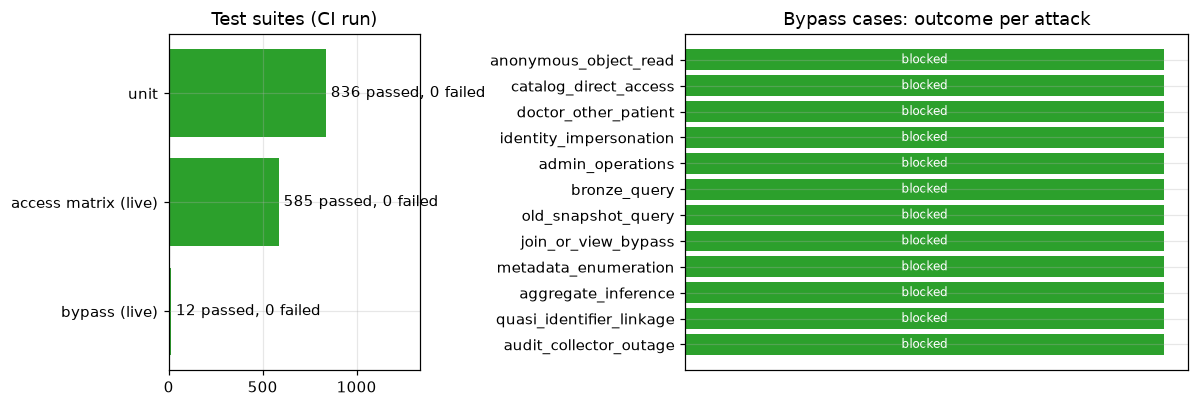

status
blocked    12
Name: count, dtype: int64

In [7]:
colors = {"blocked": "tab:green", "leaked": "tab:red", "inconclusive": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 2]})
axes[0].barh(tests.suite, tests.passed, color="tab:green", label="passed")
axes[0].barh(tests.suite, tests.failed, left=tests.passed, color="tab:red", label="failed")
for i, row in tests.iterrows():
    axes[0].text(row.passed, i, f" {row.passed} passed, {row.failed} failed", va="center")
axes[0].set_xlim(0, tests.passed.max() * 1.6)
axes[0].invert_yaxis()
axes[0].set_title("Test suites (CI run)")
axes[1].barh(cases.case, [1] * len(cases), color=[colors.get(s, "grey") for s in cases.status])
for i, status in enumerate(cases.status):
    axes[1].text(0.5, i, status, ha="center", va="center", color="white", fontsize=8)
axes[1].invert_yaxis()
axes[1].set_xticks([])
axes[1].set_title("Bypass cases: outcome per attack")
save(fig, "access-and-bypass")
cases.status.value_counts()

## 3. Audit coverage under a collector outage

`audit_collector_outage` stops the real audit collector while queries keep running,
restarts it and reconciles issued Trino query IDs against stored `QueryCreated` and
`QueryCompleted` events. Query IDs stay in private evidence; only counts are here.

,value
coverage_percent,100.0
duplicate_event_count,0
expected_event_types,"[QueryCreated, QueryCompleted]"
expected_query_count,4
invalid_event_count,0
measured_at_utc,2026-10-31T13:35:47.673223+00:00
missing_event_count,0
missing_query_count,0
observed_expected_query_count,4
outage_ended_utc,2026-10-31T13:35:34.729794+00:00


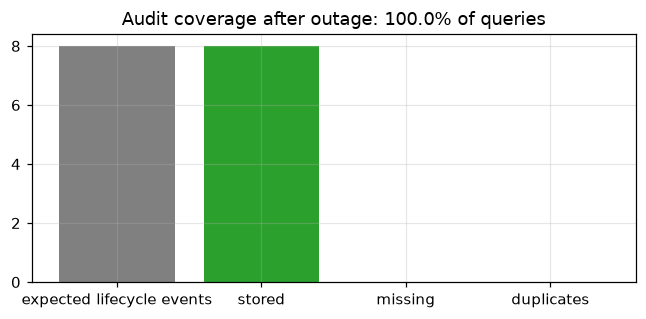

In [8]:
audit = load_json("audit-coverage.json")
expected_events = audit["expected_query_count"] * len(audit["expected_event_types"])
stored_events = expected_events - audit["missing_event_count"]
display(pd.Series(audit, name="value").to_frame())
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(
    ["expected lifecycle events", "stored", "missing", "duplicates"],
    [expected_events, stored_events, audit["missing_event_count"], audit["duplicate_event_count"]],
    color=["grey", "tab:green", "tab:red", "tab:orange"],
)
ax.set_title(f"Audit coverage after outage: {audit['coverage_percent']}% of queries")
save(fig, "audit-coverage")

## 4. Researcher privacy risk before and after #46

Same 1,009-patient synthetic cohort (1,000 Synthea patients plus boundary fixtures).
**Before:** researchers saw row-level age band, sex, masked ZIP and reason codes.
**After:** row-level quasi-identifiers are hidden and demographics, geography and
conditions are released only as `hospital.gold` aggregate tables whose cells count
at least 11 distinct patients.

In [9]:
aggregate = load_json("issue-24-aggregate-inference.json")
linkage = load_json("issue-24-quasi-identifier-linkage.json")
before = aggregate["before_mitigation"]
k_anon = before["k_anonymity"]
pd.DataFrame(
    {
        "quasi-identifiers": [
            ", ".join(k_anon["quasi_identifiers"]),
            ", ".join(before["k_anonymity_with_rare_condition_signature"]["quasi_identifiers"]),
        ],
        "equivalence classes": [
            k_anon["equivalence_classes"],
            before["k_anonymity_with_rare_condition_signature"]["equivalence_classes"],
        ],
        "k_min": [k_anon["k_min"], before["k_anonymity_with_rare_condition_signature"]["k_min"]],
        "unique patients": [
            k_anon["unique_records"],
            before["k_anonymity_with_rare_condition_signature"]["unique_records"],
        ],
        "unique %": [
            round(k_anon["unique_percent"], 2),
            round(before["k_anonymity_with_rare_condition_signature"]["unique_percent"], 2),
        ],
    },
    index=["before: demographics", "before: + rare conditions"],
)

,quasi-identifiers,equivalence classes,k_min,unique patients,unique %
before: demographics,"age_band, sex, zip",279,1,94,9.32
before: + rare conditions,"age_band, sex, zip, rare_condition_signature",832,1,759,75.22


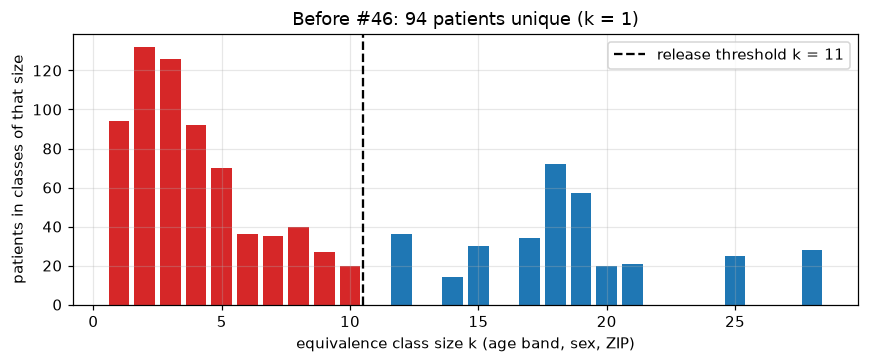

In [10]:
histogram = pd.Series(
    {int(size): count for size, count in k_anon["class_size_histogram"].items()}
).sort_index()
patients_per_size = histogram * histogram.index
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(
    histogram.index,
    patients_per_size,
    color=["tab:red" if k < MIN_CELL else "tab:blue" for k in histogram.index],
)
ax.axvline(MIN_CELL - 0.5, color="black", linestyle="--", label=f"release threshold k = {MIN_CELL}")
ax.set_xlabel("equivalence class size k (age band, sex, ZIP)")
ax.set_ylabel("patients in classes of that size")
ax.set_title(f"Before #46: {k_anon['unique_records']} patients unique (k = 1)")
ax.legend()
save(fig, "privacy-k-anonymity-before")

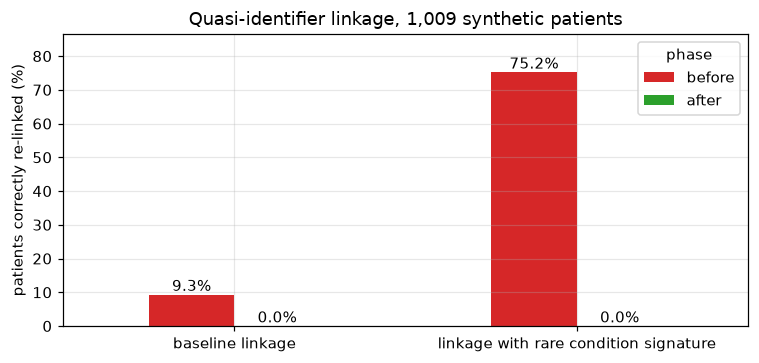

,attack,phase,correct links,linkage %
0,baseline linkage,before,94,9.32
1,baseline linkage,after,0,0.00
2,linkage with rare condition signature,before,759,75.22
3,linkage with rare condition signature,after,0,0.00


In [11]:
rows = []
for attack in ("baseline_linkage", "linkage_with_rare_condition_signature"):
    for phase in ("before_mitigation", "after_mitigation"):
        result = linkage[phase][attack]
        rows.append(
            {
                "attack": attack.replace("_", " "),
                "phase": phase.split("_")[0],
                "correct links": result["correct_links"],
                "linkage %": round(result["linkage_percent"], 2),
            }
        )
links = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7, 3.4))
pivot = links.pivot(index="attack", columns="phase", values="linkage %")[["before", "after"]]
pivot.plot.bar(ax=ax, color=["tab:red", "tab:green"], rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")
ax.set_ylabel("patients correctly re-linked (%)")
ax.set_ylim(0, pivot.max().max() * 1.15)
ax.set_xlabel("")
ax.set_title(f"Quasi-identifier linkage, {linkage['population']:,} synthetic patients")
save(fig, "privacy-linkage")
links

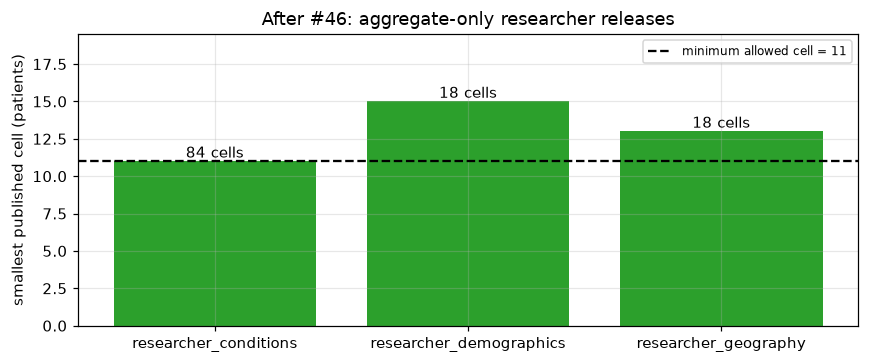

Count differencing before: 1 patient reconstructed: True
After: not possible: releases have no patient key or record-level predicate, and any cell that would fall below the threshold is absent rather than counted
Row-level quasi-identifiers visible after: []


,min_patient_count,patients_in_published_cells,published_cells
release,,,
researcher_conditions,11,7433,84
researcher_demographics,15,815,18
researcher_geography,13,998,18


In [12]:
after = aggregate["after_mitigation"]
releases = pd.DataFrame(after["releases"]).T
releases.index.name = "release"
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(releases.index, releases.min_patient_count, color="tab:green")
ax.axhline(MIN_CELL, color="black", linestyle="--", label=f"minimum allowed cell = {MIN_CELL}")
for i, (cells, smallest) in enumerate(zip(releases.published_cells, releases.min_patient_count)):
    ax.text(i, smallest, f"{int(cells)} cells", ha="center", va="bottom")
ax.set_ylabel("smallest published cell (patients)")
ax.set_title("After #46: aggregate-only researcher releases")
ax.set_ylim(0, releases.min_patient_count.max() * 1.3)
ax.legend(loc="upper right", fontsize=8)
save(fig, "privacy-releases-after")
print(
    "Count differencing before:",
    before["aggregate_inference"]["count_difference"],
    "patient reconstructed:",
    before["aggregate_inference"]["target_present_reconstructed"],
)
print("After:", after["exact_count_differencing"])
print("Row-level quasi-identifiers visible after:", after["row_level_quasi_identifiers_visible"])
releases

## 5. Limitations

- Synthetic data only (Synthea, seed 42). Linkage rates are not real-world
  re-identification probabilities.
- Benchmark ran on one shared CI runner with 10 warm repetitions; differences of a few
  percent are noise, and cold runs are single samples. No scale beyond 10,000 patients.
- `k >= 11` small-cell suppression is a mitigation threshold, not an anonymity proof.
  There is no differential-privacy budget, so differencing across releases or over time
  is not bounded. Row-level encounter codes and month-level timestamps stay visible to
  researchers.
- Audit coverage is measured for the queries issued during one controlled outage, not
  for arbitrary crash timing.